<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">Timestamped Football Odds — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">Every figure of the listing, recomputed from the files of the full product:
45,554 matches, 87,379,474 timestamped quotes, 5 named bookmakers incl. Pinnacle, 12 competitions, 2016–2026.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing,
recomputes it from the files and prints **PASS** or **FAIL**. The expected values are written once, in plain
sight, in the `CLAIMS` cell; everything else is read from the data.

⚽ **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/uooqdc?utm_source=github&utm_medium=notebook&utm_campaign=big6_premium&utm_content=notebook_top)** · free 20-match sample: same files, same columns.

## 0 · Setup

In [1]:
import os, glob, hashlib, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

def find_root():
    """Folder of the full product: the Big6_Matches.csv with the most rows wins (sample and full may both be attached)."""
    hits = []
    for base in (os.environ.get("BIG6_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += glob.glob(os.path.join(base, "**", "Big6_Matches.csv"), recursive=True)
    if not hits:
        raise FileNotFoundError("Big6_Matches.csv not found: attach the dataset to this notebook")
    return os.path.dirname(max(hits, key=os.path.getsize))

ROOT = find_root()
print("Product folder:", ROOT)

def table_files(prefix):
    """The 12 per-competition files of a table, wherever they sit under the product folder:
    .csv.gz as shipped, or .csv when the hosting platform stores them decompressed."""
    for ext in (".csv.gz", ".csv"):
        # files only: Kaggle stores each decompressed .csv.gz as a folder "X.csv" that holds the file "X.csv"
        hits = sorted(p for p in glob.glob(os.path.join(ROOT, "**", prefix + "*" + ext), recursive=True)
                      if os.path.isfile(p))
        if hits:
            return hits
    return []

def stem(path):
    """File name without folder or extension: the key of the MANIFEST row counts."""
    b = os.path.basename(path)
    return b[:-7] if b.endswith(".csv.gz") else b.rsplit(".", 1)[0]

FILES = {t: table_files(p) for t, p in (("odds", "Big6_Odds_Timestamped_"), ("events", "Big6_Events_"),
                                        ("lineups", "Big6_Lineups_"), ("minute_stats", "Big6_Minute_Stats_"))}
for t, fs in FILES.items():
    kinds = sorted({".csv.gz" if f.endswith(".gz") else ".csv" for f in fs}) or ["none found"]
    print(f"{t:13} {len(fs):>2} files  ({', '.join(kinds)})")
assert all(len(fs) == 12 for fs in FILES.values()), \
    "each table should have 12 files, one per competition: is the dataset fully processed on this platform?"

# Olivier Sports Data dark signature. HDA = home / draw / away, checked for colour-blind and normal-vision
# separation on this background.
BG, FG, FG2, GRID, CYAN = "#080c10", "#e6edf3", "#9aa7b2", "#1c2630", "#00d4ff"
HDA = {"Home": "#00a3cc", "Draw": "#c98500", "Away": "#d55181"}
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": FG2, "xtick.color": FG2, "ytick.color": FG2,
    "text.color": FG, "axes.titlecolor": FG, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10.5,
    "legend.frameon": False, "figure.dpi": 110,
})

RESULTS = []
def check(claim, ok, detail=""):
    RESULTS.append((claim, bool(ok), detail))
    print(("PASS  " if ok else "FAIL  ") + claim + (f"   [{detail}]" if detail else ""))

def epoch(s):
    """ISO 8601 UTC 'YYYY-MM-DDTHH:MM:SSZ' -> Unix seconds (NaN when empty)."""
    t = pd.to_datetime(s, format="%Y-%m-%dT%H:%M:%SZ", utc=True, errors="coerce")
    return (t - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()

BOOKS = ["Bet365", "Pinnacle", "Unibet", "Betfair", "Betsson"]

Product folder: /data/Big6_Europe_Premium_2016-2026
odds          12 files  (.csv.gz)
events        12 files  (.csv.gz)
lineups       12 files  (.csv.gz)
minute_stats  12 files  (.csv.gz)


## 1 · The claims

Copied from the listing. Nothing below is adjusted to fit: if the files disagree, the cell prints FAIL.

In [2]:
CLAIMS = {
    "matches": 45_554, "regular_season": 45_243, "play_offs": 311,
    "competitions": 12, "seasons": 11, "last_kickoff_before": "2026-10-01T00:00:00Z",
    "extra_time": 21, "penalty_shootouts": 15,
    "quotes": 87_379_474, "in_play": 59_981_836, "pre_match": 27_397_638,
    "quotes_per_book": {"Bet365": 59_584_092, "Pinnacle": 5_284_952, "Unibet": 6_031_334,
                        "Betfair": 14_334_133, "Betsson": 2_144_963},
    "ft_1x2_close_per_book": {"Bet365": 45_497, "Pinnacle": 34_004, "Unibet": 41_556,
                              "Betfair": 8_699, "Betsson": 17_226},
    "median_close_gap": {"Pinnacle": "3 min", "Betfair": "6 min", "Betsson": "8 min",
                         "Bet365": "24 min", "Unibet": "53 min"},
    "team_stats": 91_108, "lineups": 1_775_335, "events": 1_547_381, "minute_stats": 11_533_683,
}

## 2 · Every file is the one that was shipped

`MANIFEST.csv` lists each file with its row count and SHA-256 fingerprint. Recomputing the fingerprints proves
that nothing was altered between the build and this notebook.

In [3]:
man = pd.read_csv(os.path.join(ROOT, "MANIFEST.csv"), dtype=str)
located = {}
for p in glob.glob(os.path.join(ROOT, "**", "*"), recursive=True):
    if os.path.isfile(p):
        located.setdefault(os.path.basename(p), p)
t0, missing, altered, decompressed, hashed = time.time(), [], [], [], 0
for f, h in zip(man["File"], man["SHA256"]):
    p = os.path.join(ROOT, *f.split("/"))
    if not os.path.exists(p):
        p = located.get(os.path.basename(f))
    if p is None and f.endswith(".gz") and os.path.basename(f)[:-3] in located:
        decompressed.append(f); continue
    if p is None:
        missing.append(f); continue
    d = hashlib.sha256()
    with open(p, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 22), b""):
            d.update(block)
    hashed += os.path.getsize(p)
    if d.hexdigest() != h:
        altered.append(f)
print(f"{len(man)} files, {hashed / 1e9:.2f} GB hashed in {time.time() - t0:.0f} s")
check(f"all {len(man)} files present", not missing, ", ".join(missing[:5]))
check("every SHA-256 matches the MANIFEST" + (" (files kept compressed)" if decompressed else ""),
      not altered and not missing, ", ".join(altered[:5]))
if decompressed:
    print(f"Note: {len(decompressed)} .csv.gz files are stored decompressed (.csv) on this platform, so their compressed "
          "fingerprint cannot match. Their row counts are checked file by file against the MANIFEST below.")
man["Rows"] = pd.to_numeric(man["Rows"], errors="coerce")
ROWS = {stem(f): int(r) for f, r in zip(man["File"], man["Rows"]) if pd.notna(r)}
groups = man.assign(Table=man["File"].str.replace(r"(_[A-Z0-9]+_[A-Z0-9]+)?\.(csv\.gz|csv|xlsx|md)$", "", regex=True)
                                   .str.replace(r"^.*/", "", regex=True))
groups.groupby("Table").agg(files=("File", "size"), rows=("Rows", "sum")).astype(int)

55 files, 1.10 GB hashed in 4 s
PASS  all 55 files present
PASS  every SHA-256 matches the MANIFEST


,files,rows
Table,,
Big6_Events,12,1547381
Big6_Lineups,12,1775335
Big6_Matches,2,45554
Big6_Minute_Stats,12,11533683
Big6_Odds_Timestamped,12,87379474
Big6_Opening_Closing_Odds,2,45554
Big6_Team_Stats,2,91108
README,1,0


## 3 · Matches

In [4]:
M = pd.read_csv(os.path.join(ROOT, "Big6_Matches.csv"),
                dtype={"Match_ID": str, "Home_Team_ID": str, "Away_Team_ID": str, "Season": str,
                       "Home_Formation": str, "Away_Formation": str})
check(f"{CLAIMS['matches']:,} matches", len(M) == CLAIMS["matches"], f"{len(M):,}")
check("Match_ID is unique", M["Match_ID"].is_unique)
stage = M["Stage"].value_counts()
check(f"{CLAIMS['regular_season']:,} regular season + {CLAIMS['play_offs']} play-offs",
      stage.get("Regular Season", 0) == CLAIMS["regular_season"] and stage.get("Play-Offs", 0) == CLAIMS["play_offs"],
      f"{stage.get('Regular Season', 0):,} + {stage.get('Play-Offs', 0)}")
check("12 competitions, 11 seasons",
      M["Competition_Code"].nunique() == CLAIMS["competitions"] and M["Season"].nunique() == CLAIMS["seasons"],
      f"{M['Competition_Code'].nunique()} / {M['Season'].nunique()}: {M['Season'].min()} to {M['Season'].max()}")
check("last kickoff before 1 Oct 2026", M["Kickoff_UTC"].max() < CLAIMS["last_kickoff_before"], M["Kickoff_UTC"].max())
check(f"extra time on {CLAIMS['extra_time']} matches, shoot-outs on {CLAIMS['penalty_shootouts']}",
      (M["Extra_Time"] == 1).sum() == CLAIMS["extra_time"] and M["Home_Penalties"].notna().sum() == CLAIMS["penalty_shootouts"],
      f"{(M['Extra_Time'] == 1).sum()} / {M['Home_Penalties'].notna().sum()}")
res = np.select([M["Home_Goals_90"] > M["Away_Goals_90"], M["Home_Goals_90"] < M["Away_Goals_90"]], ["H", "A"], "D")
check("Result_90 agrees with the 90-minute score on every match", (res == M["Result_90"]).all())
order = ["ENG_PL", "ENG_CH", "ESP_LL", "ESP_SEG", "ITA_SA", "ITA_SB", "GER_BL", "GER_BL2", "FRA_L1", "FRA_L2", "POR_PL", "POR_SL"]
pd.crosstab(M["Competition_Code"], M["Season"]).reindex(order)

PASS  45,554 matches   [45,554]
PASS  Match_ID is unique
PASS  45,243 regular season + 311 play-offs   [45,243 + 311]
PASS  12 competitions, 11 seasons   [12 / 11: 2016/17 to 2026/27]
PASS  last kickoff before 1 Oct 2026   [2026-09-28T18:30:00Z]
PASS  extra time on 21 matches, shoot-outs on 15   [21 / 15]
PASS  Result_90 agrees with the 90-minute score on every match


Season,2016/17,2017/18,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25,2025/26,2026/27
Competition_Code,,,,,,,,,,,
ENG_PL,352,380,380,380,380,380,380,380,380,380,50
ENG_CH,497,557,557,557,557,557,557,557,557,557,95
ESP_LL,364,380,380,380,380,380,380,380,380,380,69
ESP_SEG,451,468,457,468,467,468,468,468,468,468,77
ITA_SA,368,380,379,380,379,380,381,380,380,380,50
ITA_SB,462,472,352,390,388,390,389,390,389,390,50
GER_BL,301,308,308,308,308,308,308,308,307,308,36
GER_BL2,281,308,308,308,308,308,308,308,308,308,54
FRA_L1,354,384,382,279,382,382,380,308,308,309,44


## 4 · Opening and closing prices

One row per match. For each book and market: the first and the last valid pre-match quote, each with the time
it was recorded. The listing says a closing price is never an in-play price, so every closing time must sit
strictly before the scheduled kickoff.

In [5]:
head = pd.read_csv(os.path.join(ROOT, "Big6_Opening_Closing_Odds.csv"), nrows=0).columns
OC = pd.read_csv(os.path.join(ROOT, "Big6_Opening_Closing_Odds.csv"),
                 dtype={c: str for c in head if c.endswith(("_Open_Time", "_Close_Time")) or c in ("Match_ID", "Season")})
check("one Opening_Closing row per match, same Match_IDs as Matches",
      len(OC) == len(M) and set(OC["Match_ID"]) == set(M["Match_ID"]))
kick = OC["Kickoff_Epoch"].astype("int64")
late, inverted, n_close = 0, 0, 0
for c in [c for c in OC.columns if c.endswith("_Close_Time")]:
    close = epoch(OC[c]); opened = epoch(OC[c.replace("_Close_", "_Open_")])
    n_close += close.notna().sum()
    late += (close >= kick).sum()
    inverted += (opened > close).sum()
check(f"all {n_close:,} closing times are before the scheduled kickoff", late == 0, f"{late} after")
check("opening time <= closing time everywhere", inverted == 0, f"{inverted} inverted")

cov = {b: OC[f"{b}_FT_1X2_Close_Time"].notna().sum() for b in BOOKS}
check("matches with a FT 1X2 close, per book, as listed", cov == CLAIMS["ft_1x2_close_per_book"],
      " · ".join(f"{b} {n:,}" for b, n in cov.items()))

PASS  one Opening_Closing row per match, same Match_IDs as Matches


PASS  all 519,950 closing times are before the scheduled kickoff   [0 after]
PASS  opening time <= closing time everywhere   [0 inverted]
PASS  matches with a FT 1X2 close, per book, as listed   [Bet365 45,497 · Pinnacle 34,004 · Unibet 41,556 · Betfair 8,699 · Betsson 17,226]


### Coverage by season — share of matches with a FT 1X2 closing price

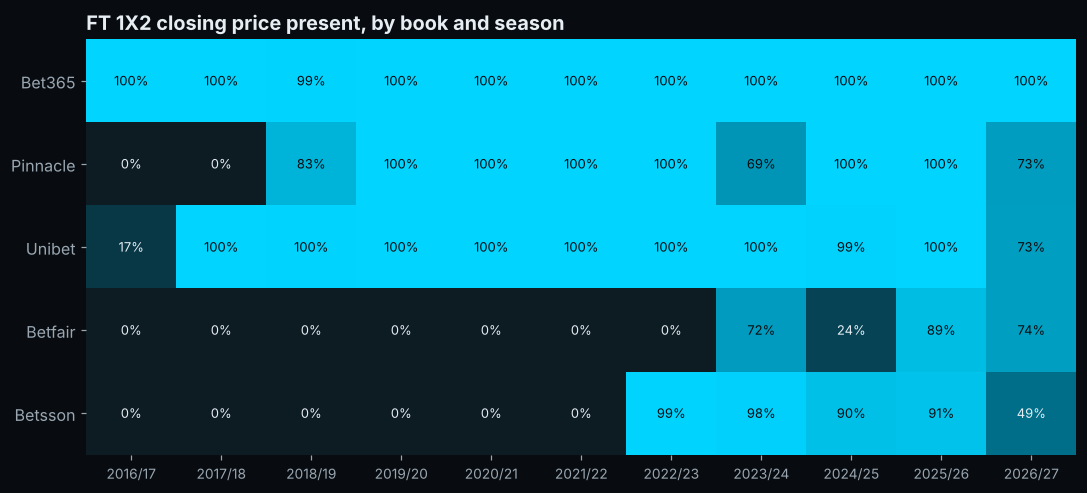

In [6]:
share = pd.DataFrame({b: OC.groupby("Season")[f"{b}_FT_1X2_Close_Time"].apply(lambda s: s.notna().mean()) for b in BOOKS})
cmap = LinearSegmentedColormap.from_list("cyan", ["#0d1b22", "#00708c", CYAN])
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.imshow(share.T.values, aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(share.index)), share.index, rotation=0, fontsize=9)
ax.set_yticks(range(len(BOOKS)), BOOKS)
ax.grid(False)
for i, b in enumerate(BOOKS):
    for j, s in enumerate(share.index):
        v = share.loc[s, b]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8.5, color="#080c10" if v > 0.6 else FG)
ax.set_title("FT 1X2 closing price present, by book and season")
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

### How close to kickoff is a "closing" price?

A closing quote is the last pre-match price the book published. Books update at different rhythms, so each one
gets its own closing time. Below: median and interquartile range of the gap to kickoff, FT 1X2.

PASS  median closing gap per book, as listed   [Pinnacle 3 min · Betfair 6 min · Betsson 8 min · Bet365 24 min · Unibet 53 min]


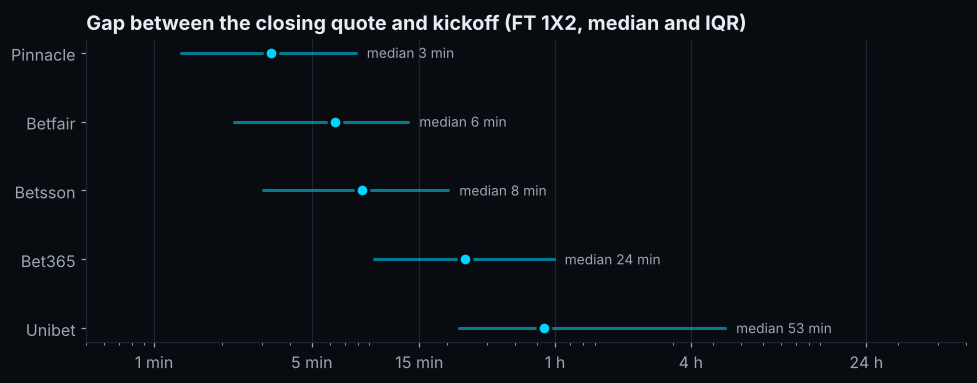

In [7]:
def upper_median(v):
    v = np.sort(np.asarray(v)); return v[len(v) // 2]

def readable(s):
    return f"{s / 3600:.1f} h" if s >= 5400 else f"{s / 60:.0f} min"

gaps = {}
for b in BOOKS:
    g = (kick - epoch(OC[f"{b}_FT_1X2_Close_Time"])).dropna().to_numpy()
    gaps[b] = g
got = {b: readable(upper_median(g)) for b, g in gaps.items()}
check("median closing gap per book, as listed", all(got[b] == CLAIMS["median_close_gap"][b] for b in BOOKS),
      " · ".join(f"{b} {got[b]}" for b in sorted(got, key=lambda b: upper_median(gaps[b]))))

books = sorted(BOOKS, key=lambda b: upper_median(gaps[b]), reverse=True)
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, b in enumerate(books):
    q1, q2, q3 = np.percentile(gaps[b] / 60, [25, 50, 75])
    ax.plot([q1, q3], [i, i], color=CYAN, linewidth=2, solid_capstyle="round", alpha=0.55)
    ax.scatter([q2], [i], s=70, color=CYAN, zorder=3, edgecolor=BG, linewidth=2)
    ax.text(q3 * 1.12, i, f"median {readable(upper_median(gaps[b]))}", va="center", fontsize=9, color=FG2)
ax.set_xscale("log")
ax.set_xticks([1, 5, 15, 60, 240, 1440], ["1 min", "5 min", "15 min", "1 h", "4 h", "24 h"])
ax.set_yticks(range(len(books)), books)
ax.set_xlim(0.5, 4000)
ax.grid(axis="y", visible=False)
ax.set_title("Gap between the closing quote and kickoff (FT 1X2, median and IQR)")
plt.tight_layout(); plt.show()

### Are these real market prices?

A real closing line is better informed than the opening one: its implied probabilities should predict results
better. Probabilities are de-margined proportionally; lower log-loss is better. Compare open and close **within a
book** — books cover different sets of matches, so the rows are not comparable with each other.

In [8]:
y = OC["Result_90"].map({"H": 0, "D": 1, "A": 2}).to_numpy()
rows = []
for b in BOOKS:
    cols = lambda k: [f"{b}_FT_1X2_{k}_{s}" for s in ("Home", "Draw", "Away")]
    o, c = OC[cols("Open")].to_numpy(float), OC[cols("Close")].to_numpy(float)
    ok = ~np.isnan(o).any(1) & ~np.isnan(c).any(1)
    def logloss(x):
        p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
        return -np.log(p[np.arange(ok.sum()), y[ok]]).mean()
    rows.append((b, ok.sum(), logloss(o), logloss(c), (1 / o[ok]).sum(1).mean() - 1, (1 / c[ok]).sum(1).mean() - 1))
LL = pd.DataFrame(rows, columns=["Book", "Matches", "LogLoss open", "LogLoss close", "Margin open", "Margin close"]).set_index("Book")
check("closing beats opening on log-loss, for every book", (LL["LogLoss close"] < LL["LogLoss open"]).all())
LL.style.format({"Matches": "{:,}", "LogLoss open": "{:.4f}", "LogLoss close": "{:.4f}",
                 "Margin open": "{:.2%}", "Margin close": "{:.2%}"})

PASS  closing beats opening on log-loss, for every book


,Matches,LogLoss open,LogLoss close,Margin open,Margin close
Book,,,,,
Bet365,"45,497",1.0086,1.0009,7.08%,5.97%
Pinnacle,"34,004",1.0106,1.0034,4.70%,3.12%
Unibet,"41,556",1.0066,1.0015,6.45%,6.13%
Betfair,"8,699",1.0068,1.0008,8.05%,10.39%
Betsson,"17,226",1.0049,1.0006,5.87%,5.88%


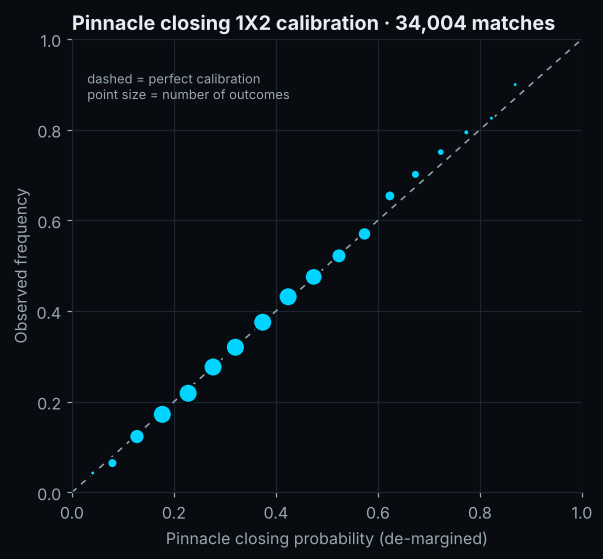

In [9]:
# Pinnacle closing 1X2: predicted probability vs observed frequency (all three outcomes pooled)
cols = [f"Pinnacle_FT_1X2_Close_{s}" for s in ("Home", "Draw", "Away")]
x = OC[cols].to_numpy(float); ok = ~np.isnan(x).any(1)
p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
hit = np.zeros_like(p); hit[np.arange(ok.sum()), y[ok]] = 1
cal = pd.DataFrame({"p": p.ravel(), "hit": hit.ravel()})
cal["bin"] = pd.cut(cal["p"], np.arange(0, 1.0001, 0.05))
cb = cal.groupby("bin", observed=True).agg(p=("p", "mean"), freq=("hit", "mean"), n=("hit", "size"))
cb = cb[cb["n"] >= 50]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=FG2, linewidth=1, linestyle=(0, (4, 4)))
ax.scatter(cb["p"], cb["freq"], s=np.clip(cb["n"] / 40, 12, 160), color=CYAN, edgecolor=BG, linewidth=1.5, zorder=3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Pinnacle closing probability (de-margined)"); ax.set_ylabel("Observed frequency")
ax.set_title(f"Pinnacle closing 1X2 calibration · {ok.sum():,} matches")
ax.text(0.03, 0.93, "dashed = perfect calibration\npoint size = number of outcomes", fontsize=8.5, color=FG2, va="top")
plt.tight_layout(); plt.show()

## 5 · 87 million timestamped quotes

One pass over the 12 odds files (about 1 GB compressed), a few columns at a time. Checked on every row:
a **pre-match** quote carries no score and was recorded before the scheduled kickoff.

In [10]:
kick_by_id = pd.Series(M["Kickoff_Epoch"].to_numpy("int64"), index=M["Match_ID"].astype("int64"))
season_by_id = pd.Series(M["Season"].to_numpy(), index=M["Match_ID"].astype("int64"))
use = ["Match_ID", "Book", "Phase", "Epoch", "Score_Home", "Suspended"]

def read(path, cols):
    try:
        d = pd.read_csv(path, usecols=cols, engine="pyarrow")   # fast, multi-threaded
    except Exception:
        d = pd.read_csv(path, usecols=cols)
    for c in d.columns:   # the pyarrow reader turns ISO times into datetimes: show them as written in the file
        if pd.api.types.is_datetime64_any_dtype(d[c]):
            d[c] = d[c].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
    return d

t0 = time.time()
by_book_phase, by_book_season = [], []
pre_scored = pre_late = inplay_scored = n_rows = 0
off_manifest = []
for f in FILES["odds"]:
    d = read(f, use)
    n_rows += len(d)
    if len(d) != ROWS.get(stem(f)):
        off_manifest.append(stem(f))
    pre = d["Phase"] == "Pre-match"
    pre_scored += (pre & d["Score_Home"].notna()).sum()
    pre_late += (pre & (d["Epoch"].to_numpy() >= kick_by_id.reindex(d["Match_ID"]).to_numpy())).sum()
    inplay_scored += (~pre & d["Score_Home"].notna()).sum()
    by_book_phase.append(d.groupby(["Book", "Phase"]).size())
    by_book_season.append(d.groupby([d["Book"], season_by_id.reindex(d["Match_ID"]).to_numpy()]).size())
    print(f"{os.path.basename(f):42} {len(d):>12,} quotes   {time.time() - t0:5.0f} s")
    del d

bp = pd.concat(by_book_phase).groupby(level=[0, 1]).sum().unstack(fill_value=0)
phase = bp.sum()
check(f"{CLAIMS['quotes']:,} quotes, every file equal to the MANIFEST", n_rows == CLAIMS["quotes"] and not off_manifest,
      f"{n_rows:,}" + (f", off: {', '.join(off_manifest)}" if off_manifest else ""))
check("in-play / pre-match split as listed",
      phase.get("In-play", 0) == CLAIMS["in_play"] and phase.get("Pre-match", 0) == CLAIMS["pre_match"],
      f"{phase.get('In-play', 0):,} in-play · {phase.get('Pre-match', 0):,} pre-match")
check("quotes per book as listed", bp.sum(axis=1).to_dict() == CLAIMS["quotes_per_book"])
check("no pre-match quote carries a score", pre_scored == 0, f"{pre_scored}")
check("every pre-match quote is before the scheduled kickoff", pre_late == 0, f"{pre_late}")
print(f"in-play quotes with the score attached: {inplay_scored / phase.get('In-play', 1):.1%}")
bp.assign(Total=bp.sum(axis=1)).reindex(BOOKS).style.format("{:,}")

Big6_Odds_Timestamped_ENG_CH.csv.gz           9,564,047 quotes       7 s


Big6_Odds_Timestamped_ENG_PL.csv.gz           8,821,446 quotes      13 s


Big6_Odds_Timestamped_ESP_LL.csv.gz           9,278,459 quotes      20 s


Big6_Odds_Timestamped_ESP_SEG.csv.gz          8,432,701 quotes      26 s


Big6_Odds_Timestamped_FRA_L1.csv.gz           6,640,684 quotes      30 s


...

Big6_Odds_Timestamped_ITA_SA.csv.gz           8,981,251 quotes      49 s


Big6_Odds_Timestamped_ITA_SB.csv.gz           6,434,585 quotes      53 s


Big6_Odds_Timestamped_POR_PL.csv.gz           6,533,856 quotes      57 s


Big6_Odds_Timestamped_POR_SL.csv.gz           4,957,975 quotes      60 s
PASS  87,379,474 quotes, every file equal to the MANIFEST   [87,379,474]
PASS  in-play / pre-match split as listed   [59,981,836 in-play · 27,397,638 pre-match]
PASS  quotes per book as listed
PASS  no pre-match quote carries a score   [0]
PASS  every pre-match quote is before the scheduled kickoff   [0]
in-play quotes with the score attached: 96.6%


Phase,In-play,Pre-match,Total
Book,,,
Bet365,"50,637,226","8,946,866","59,584,092"
Pinnacle,"257,534","5,027,418","5,284,952"
Unibet,"5,413,948","617,386","6,031,334"
Betfair,"2,340,574","11,993,559","14,334,133"
Betsson,"1,332,554","812,409","2,144,963"


Quotes per match, all markets, by season: how often each book updated its prices. Betfair (Sportsbook) updates mostly before kickoff, Bet365 mostly in play.

In [11]:
bs = pd.concat(by_book_season).groupby(level=[0, 1]).sum().unstack(level=0, fill_value=0).reindex(columns=BOOKS)
matches_per_season = M.groupby("Season").size()
(bs.div(matches_per_season, axis=0)).round(0).astype(int).rename_axis("Quotes per match").style.format("{:,}")

Book,Bet365,Pinnacle,Unibet,Betfair,Betsson
Quotes per match,,,,,
2016/17,342,0,38,0,0
2017/18,853,0,114,0,0
2018/19,"1,014",55,121,0,0
2019/20,"1,460",232,137,0,0
2020/21,"1,633",204,137,0,0
2021/22,"1,322",170,136,0,0
2022/23,"1,377",94,155,0,182
2023/24,"1,852",88,167,"2,073",120
2024/25,"1,956",132,143,651,60


### Lineups, events, minute-by-minute stats

Rows counted from the files themselves, and every row must join a match of `Big6_Matches` on `Match_ID`.

In [12]:
ids = set(M["Match_ID"].astype("int64"))
for folder, claim in (("lineups", "lineups"), ("events", "events"), ("minute_stats", "minute_stats")):
    n, orphans, off = 0, 0, []
    for f in FILES[folder]:
        d = read(f, ["Match_ID"])
        n += len(d)
        orphans += (~d["Match_ID"].isin(ids)).sum()
        if len(d) != ROWS.get(stem(f)):
            off.append(stem(f))
    check(f"{CLAIMS[claim]:,} {folder.replace('_', ' ')} rows, all joined to a match", n == CLAIMS[claim] and orphans == 0 and not off,
          f"{n:,} rows, {orphans} without a match" + (f", off the MANIFEST: {', '.join(off)}" if off else ""))

PASS  1,775,335 lineups rows, all joined to a match   [1,775,335 rows, 0 without a match]


PASS  1,547,381 events rows, all joined to a match   [1,547,381 rows, 0 without a match]


PASS  11,533,683 minute stats rows, all joined to a match   [11,533,683 rows, 0 without a match]


## 6 · One match, quote by quote

The table shown in the listing: Everton 3-3 Man City, Premier League, 4 May 2026, Bet365 full-time 1X2 in play.
Recomputed here from `Big6_Odds_Timestamped_ENG_PL.csv.gz`, then drawn as implied probabilities, with the goals
of the events table on top. The events table counts the minute being played (a goal at 42:30 is 43'), Bet365's
clock counts the minutes elapsed (42): that is the one-minute gap between a dotted line and the price jump.

In [13]:
MID = 10720537
cols = ["Match_ID", "Book", "Market", "Phase", "Timestamp_UTC", "Epoch", "Minute",
        "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away", "Suspended"]
pl = read(next(f for f in FILES["odds"] if stem(f).endswith("_ENG_PL")), cols)
one = pl[pl["Match_ID"] == MID]
del pl
t = one[(one["Book"] == "Bet365") & (one["Market"] == "FT_1X2") & (one["Phase"] == "In-play")].sort_values("Epoch", kind="stable")
t = t.reset_index(drop=True)

# the listing's rule: around each score change, the quote before and the quote at the change
keep, last = [], None
for i, sc in enumerate(zip(t["Score_Home"].fillna(-1), t["Score_Away"].fillna(-1))):
    if sc != last:
        keep += [k for k in (i - 1, i) if k >= 0 and k not in keep]
        last = sc
show = (t.loc[keep[:16], ["Timestamp_UTC", "Minute", "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away"]]
          .astype({"Minute": "Int64", "Score_Home": "Int64", "Score_Away": "Int64"}))
print(f"{len(t)} in-play Bet365 1X2 quotes on this match")
show

229 in-play Bet365 1X2 quotes on this match


,Timestamp_UTC,Minute,Score_Home,Score_Away,Price_Home,Price_Draw,Price_Away
0,2026-05-04T19:02:57Z,2,0,0,6.500,4.75,1.500
66,2026-05-04T19:42:03Z,41,0,0,7.500,3.60,1.533
67,2026-05-04T19:42:40Z,42,0,1,21.000,7.00,1.142
124,2026-05-04T20:26:55Z,68,0,1,NaN,NaN,NaN
125,2026-05-04T20:26:57Z,68,1,1,7.500,2.20,2.100
144,2026-05-04T20:31:32Z,72,1,1,NaN,NaN,NaN
145,2026-05-04T20:31:38Z,72,2,1,1.727,3.00,6.500
171,2026-05-04T20:39:37Z,80,2,1,1.533,3.25,10.000
172,2026-05-04T20:39:45Z,80,3,1,NaN,NaN,NaN
178,2026-05-04T20:41:11Z,82,3,1,1.050,12.00,41.000


 Minute  Added_Time Team_Side  Player
   43.0         NaN      Away    Doku
   68.0         NaN      Home   Barry
   73.0         NaN      Home O'Brien
   81.0         NaN      Home   Barry
   83.0         NaN      Away Haaland
   90.0         7.0      Away    Doku


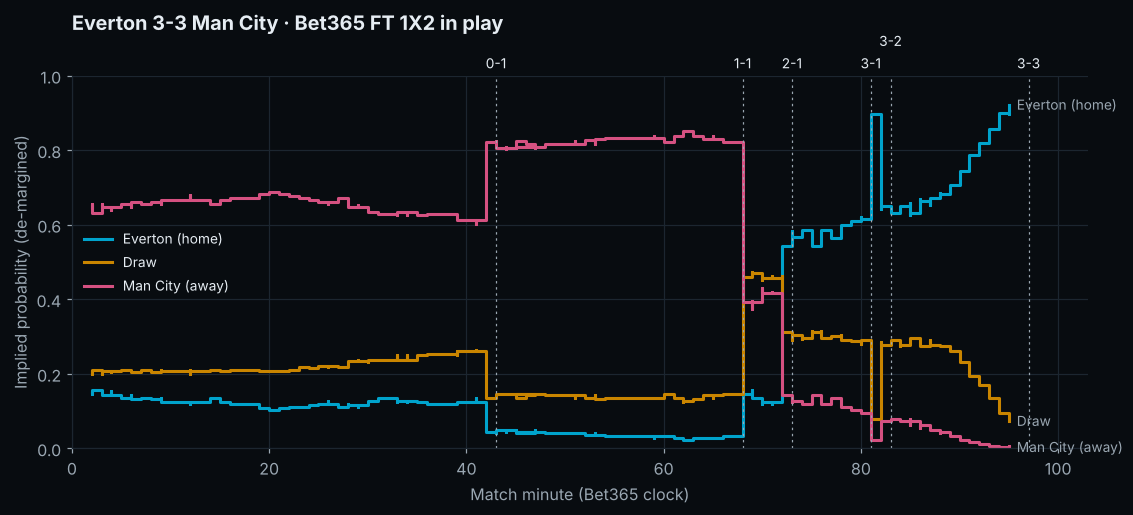

In [14]:
ev = read(next(f for f in FILES["events"] if stem(f).endswith("_ENG_PL")),
          ["Match_ID", "Minute", "Added_Time", "Event_Type", "Team_Side", "Player"])
goals = ev[(ev["Match_ID"] == MID) & (ev["Event_Type"] == "Goal")].sort_values(["Minute", "Added_Time"], na_position="first")
print(goals[["Minute", "Added_Time", "Team_Side", "Player"]].to_string(index=False))

live = t[t["Suspended"] == 0].copy()
inv = 1 / live[["Price_Home", "Price_Draw", "Price_Away"]]
prob = inv.div(inv.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
x = live["Minute"]
names = {"Price_Home": "Everton (home)", "Price_Draw": "Draw", "Price_Away": "Man City (away)"}
for col, side in zip(prob.columns, ["Home", "Draw", "Away"]):
    ax.plot(x, prob[col], color=HDA[side], linewidth=2, label=names[col], drawstyle="steps-post")
    ax.text(x.iloc[-1] + 0.8, prob[col].iloc[-1], names[col], color=FG2, fontsize=9, va="center")
score_h = score_a = 0
previous, level = -99, 0
for _, g in goals.iterrows():
    m = g["Minute"] + (0 if pd.isna(g["Added_Time"]) else g["Added_Time"])
    score_h += g["Team_Side"] == "Home"; score_a += g["Team_Side"] == "Away"
    level = 1 - level if m - previous < 5 else 0          # stagger labels of goals close together
    previous = m
    ax.axvline(m, color=FG2, linewidth=0.8, linestyle=(0, (2, 3)))
    ax.text(m, 1.02 + 0.06 * level, f"{score_h}-{score_a}", ha="center", fontsize=9, color=FG,
            transform=ax.get_xaxis_transform())
ax.set_ylim(0, 1); ax.set_xlim(0, max(97, x.max() + 8))
ax.set_xlabel("Match minute (Bet365 clock)"); ax.set_ylabel("Implied probability (de-margined)")
ax.set_title("Everton 3-3 Man City · Bet365 FT 1X2 in play", pad=30)
ax.legend(loc="center left", fontsize=9)
plt.tight_layout(); plt.show()

## 7 · Nothing a spreadsheet can reinterpret

Formations are digits (4231 = 4-2-3-1), timestamps carry the T and the Z, and no text cell starts with a
character a spreadsheet would read as a formula or turn into a date.

In [15]:
iso = re.compile(r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}Z$")
risky = re.compile(r"^([=+@\-]|\d{1,2}[-/]\d{1,2}([-/]\d{2,4})?$|\d{1,2}:\d{2}(:\d{2})?$)")
form = pd.concat([M["Home_Formation"], M["Away_Formation"]]).dropna()
check("formations are digits that add up to 10 players",
      form.str.fullmatch(r"\d{3,5}").all() and form.map(lambda s: sum(map(int, s)) == 10).all(),
      f"{len(form):,} formations, e.g. {form.value_counts().index[0]}")
times = pd.concat([M["Kickoff_UTC"]] + [OC[c].dropna() for c in OC.columns if c.endswith(("_Open_Time", "_Close_Time"))])
check("every timestamp is ISO 8601 with T and Z", times.map(lambda s: bool(iso.match(s))).all(), f"{len(times):,} cells")
TS = pd.read_csv(os.path.join(ROOT, "Big6_Team_Stats.csv"), dtype=str)
is_text = lambda s: s.dtype == object or isinstance(s.dtype, pd.StringDtype)
text_cells = pd.concat([df[c].dropna().astype(str) for df in (M, OC, TS) for c in df.columns if is_text(df[c])
                        and not c.endswith(("_Open_Time", "_Close_Time", "_UTC")) and c != "Season"])
bad = text_cells[text_cells.map(lambda s: bool(risky.match(s)))]
check("no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)", bad.empty,
      f"{len(text_cells):,} text cells" + (f", e.g. {bad.iloc[0]!r}" if len(bad) else ""))
check(f"{CLAIMS['team_stats']:,} team-stat rows, two per match", len(TS) == CLAIMS["team_stats"] == 2 * len(M))

PASS  formations are digits that add up to 10 players   [51,707 formations, e.g. 4231]


PASS  every timestamp is ISO 8601 with T and Z   [1,085,454 cells]


PASS  no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)   [3,351,740 text cells]
PASS  91,108 team-stat rows, two per match


## 8 · Summary

In [16]:
summary = pd.DataFrame(RESULTS, columns=["Claim", "Pass", "Detail"])
print(f"{summary['Pass'].sum()} / {len(summary)} claims verified")
summary.assign(Result=summary["Pass"].map({True: "PASS", False: "FAIL"}))[["Result", "Claim", "Detail"]].style.hide(axis="index")

27 / 27 claims verified


Result,Claim,Detail
PASS,all 55 files present,
PASS,every SHA-256 matches the MANIFEST,
PASS,"45,554 matches","45,554"
PASS,Match_ID is unique,
PASS,"45,243 regular season + 311 play-offs","45,243 + 311"
PASS,"12 competitions, 11 seasons",12 / 11: 2016/17 to 2026/27
PASS,last kickoff before 1 Oct 2026,2026-09-28T18:30:00Z
PASS,"extra time on 21 matches, shoot-outs on 15",21 / 15
PASS,Result_90 agrees with the 90-minute score on every match,
PASS,"one Opening_Closing row per match, same Match_IDs as Matches",


---

Everything above ran on the files a buyer downloads. The README in the ZIP holds the full column dictionary,
the coverage by season, the 17 removed source events with their evidence, and every known limitation.

👉 ⚽ **[→ Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/uooqdc?utm_source=github&utm_medium=notebook&utm_campaign=big6_premium&utm_content=notebook_bottom)** 👈

A question before buying: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*